# 05 — Anomaly investigation: 4 case studies (A19)

Owner: Arva. Four test-period user-days are taken apart the way an analyst would: who and when (step 2), how the day differs from the user's own baseline (step 3), what each model reacted to (step 4, figure **F7**), and the raw events behind the features (step 5).

- **Picks (step 1):** Isolation Forest at its best-F1 threshold (chosen on val). For each scenario the highest-scoring flagged malicious day, or the scenario's highest-scoring *missed* day if none is flagged; plus the highest-scoring normal day (the top false positive). The rule is `pipeline.pick_cases()`; **Arva confirms the picks [H]**.
- **Models:** both detectors are retrained here with the tuned defaults (A16), so no saved model is reused.
- **Data:** `features_v1.parquet`, the 4 small Parquet logs and the web cache from the data drop. `http.parquet` is not needed.
- **Human-only (TEAM_PLAN 2.6):** the narrative and the analyst verdict of every case are Arva's to write, in the marked cells. Nothing in this notebook interprets the results.

Run with Restart & Run All (about 2 minutes).

In [1]:
import io
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import explain, pipeline
from src.config import FIGURES_DIR, PROCESSED_DIR, TABLES_DIR
from src.evaluate import threshold_best_f1
from src.features import get_model_matrix
from src.models_unsupervised import SCORE_KEYS
from src.risk_scoring import HIGH, MEDIUM, score_risk

pd.set_option('display.max_columns', 30, 'display.max_colwidth', 90, 'display.width', 200)

FEATURES = PROCESSED_DIR / 'features_v1.parquet'
df = pd.read_parquet(FEATURES)
X, _, names = get_model_matrix(df)

detectors, risks = {}, {}
for model in ('iforest', 'autoencoder'):
    detectors[model], path, _ = pipeline.get_detector(df, model, FEATURES, retrain=True)
    scores = df[SCORE_KEYS].copy()
    scores['score'] = detectors[model].score(X)
    risks[model] = score_risk(scores)

risk = risks['iforest']
threshold = threshold_best_f1(risk[risk['split'] == 'val'])
test = risk[risk['split'] == 'test']
print(f'{len(df):,} user-days, {len(names)} model inputs; alert levels High >= {HIGH:g}, Medium >= {MEDIUM:g}')
print(f'Isolation Forest best-F1 threshold (from val): {threshold:.4f}')
print(f'test user-days at or above it: {int((test.score >= threshold).sum()):,} of {len(test):,}')
flagged = test[test.label == 1].assign(flagged=lambda t: t.score >= threshold)
flagged.groupby('scenario').flagged.agg(malicious_days='size', flagged_days='sum')

330,268 user-days, 76 model inputs; alert levels High >= 99, Medium >= 95
Isolation Forest best-F1 threshold (from val): -0.0365
test user-days at or above it: 7,604 of 65,007


,malicious_days,flagged_days
scenario,,
1,9,9
2,157,78
3,4,2


## Steps 1–2: the four cases and their context

One row per case: user, role, date, the Isolation Forest score against its threshold, daily risk, 7-day user risk and the alert level (from the user risk). `kind` says whether the day was flagged (`true positive`), not flagged (`missed`: tell Ayo for the FP/FN analysis) or is the top normal day (`false positive`). The autoencoder's daily risk for the same day is added for comparison, and the 3 reasons are the ones the prototype would show for that day.

In [2]:
cases = pipeline.pick_cases(risk, threshold, df)
cases['ae_daily_risk'] = risks['autoencoder'].loc[cases.index, 'daily_risk']
for model in ('iforest', 'autoencoder'):
    contrib = pipeline.contributions(detectors[model], model, X.loc[cases.index], df)
    cases[f'reasons_{model}'] = pipeline.alert_reasons(contrib, df).reindex(cases.index)
cases.insert(0, 'case_id', [f'case{i}' for i in range(1, len(cases) + 1)])
TABLES_DIR.mkdir(parents=True, exist_ok=True)
cases.to_csv(TABLES_DIR / 'case_studies.csv', index=False)
print('saved', (TABLES_DIR / 'case_studies.csv').relative_to(ROOT))
cases.round({c: 4 for c in cases.select_dtypes('float').columns})

saved results\tables\case_studies.csv


,case_id,case,kind,user,date,role,department,scenario,label,score,threshold,daily_risk,user_risk,alert_level,ae_daily_risk,reasons_iforest,reasons_autoencoder
315658,case1,scenario 1,true positive,WDD0366,2011-02-24,ITAdmin,6 - Security,1,1,0.1326,-0.0365,99.5357,99.5357,High,100.0000,after-hours events 11.6σ above own baseline; first logon on a new PC; hours between fi...,leak-site visits 1.0σ above own baseline; leak-site visits 0.8σ above peers; neurotici...
71225,case2,scenario 2,true positive,CQW0652,2011-03-22,Technician,3 - FieldService,2,1,0.1030,-0.0365,99.2484,99.2484,High,98.1122,after-hours events 2.2σ above own baseline; files copied 1.9σ above own baseline; USB ...,mean email size (bytes): 40003.3; 3 images copied; extraversion score: 48
167490,case3,scenario 3,true positive,JLM0364,2011-04-28,ITAdmin,6 - Security,3,1,0.1670,-0.0365,99.8293,99.8293,High,100.0000,after-hours events 11.0σ above own baseline; web visits 7.0σ above own baseline; keylo...,keylogger/hacking-site visits 6.0σ above own baseline; first-ever USB use; job-site vi...
11405,case4,top normal day,false positive,AJF0370,2011-04-11,ITAdmin,6 - Security,0,0,0.2195,-0.0365,100.0000,100.0000,High,95.6934,first logon on a new PC; after-hours events 1.8σ above own baseline; email recipients ...,USB connects 1.0σ above own baseline; 3 archives copied; 2 competitor-site visits


**Picks confirmed (Arva) [H]:** *check the four rows above against the rule and write here that you confirm them, or which case you replace and why.*

In [3]:
EVIDENCE_ROWS = 25      # rows shown per log; the count line gives the total


def show(fig, dpi=80):
    """Show a saved (closed) figure at screen size; the 300 dpi files are in results/figures/."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=dpi, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


def case(i):
    row = cases.index[i - 1]
    c = cases.loc[row]
    return row, c, f"case {i} ({c['case']}, {c['kind']}): {c['user']} on {pd.Timestamp(c['date']).date()}"


def baseline(i):
    """Step 3: the top 5 baselined features by |z_user|."""
    row, c, title = case(i)
    print(title)
    return pipeline.baseline_vs_day(df, row, k=5).round(2)


def figures(i):
    """Step 4 (F7): Isolation Forest SHAP waterfall + the autoencoder's 10 largest feature errors."""
    row, c, title = case(i)
    stem = f'F7_case{i}'
    sv, X_row = pipeline.shap_for_row(detectors['iforest'], X, df, row)
    show(explain.plot_waterfall(sv, X_row, 0, name=f'{stem}_iforest_shap'))
    fig, errors = pipeline.plot_ae_errors(detectors['autoencoder'], X, row, f'{stem}_autoencoder_errors',
                                          title=f"Autoencoder, {c['user']} {pd.Timestamp(c['date']).date()}")
    show(fig)
    print(title)
    print('saved', ', '.join(sorted(p.name for p in FIGURES_DIR.glob(f'{stem}_*'))))
    return errors.round(3)


def evidence(i):
    """Step 5: the raw events of that user-day and its web domains."""
    row, c, title = case(i)
    print(title)
    for name, events in pipeline.raw_evidence(c['user'], c['date']).items():
        shown = '' if len(events) <= EVIDENCE_ROWS else f' (first {EVIDENCE_ROWS} shown)'
        extra = ''
        if name == 'web' and len(events):
            flagged = events[events.category != 'other']
            extra = (f"; {int(events.visits.sum())} visits, {int(events.afterhours.sum())} after hours, "
                     f"{len(flagged)} domains in a keyword category")
        print(f'\n{name}: {len(events)} rows{extra}{shown}')
        if len(events):
            display(events.head(EVIDENCE_ROWS))

## Case 1: scenario 1

Step 3: the day against the user's own previous 30 active days and against same-role peers that day.

In [4]:
baseline(1)

case 1 (scenario 1, true positive): WDD0366 on 2011-02-24


,feature,what,value,mean_previous_days,previous_days,z_user,z_peer
0,f_afterhours_events,after-hours events,57.00,4.83,30,11.63,3.97
1,f_work_duration,hours between first logon and last logoff,22.50,15.08,30,1.68,1.61
2,f_first_logon_hour,first logon hour,0.68,5.20,30,-1.18,-0.97
3,f_http_leak,leak-site visits,1.00,0.00,30,1.00,0.80
4,f_http_count,web visits,115.00,114.00,30,1.00,0.33


Step 4 (F7): what each model reacted to. Left to right in the SHAP waterfall, red pushes the Isolation Forest score towards "anomalous"; the values shown are the raw feature values. In the bar chart, red bars are values above what the autoencoder expected.

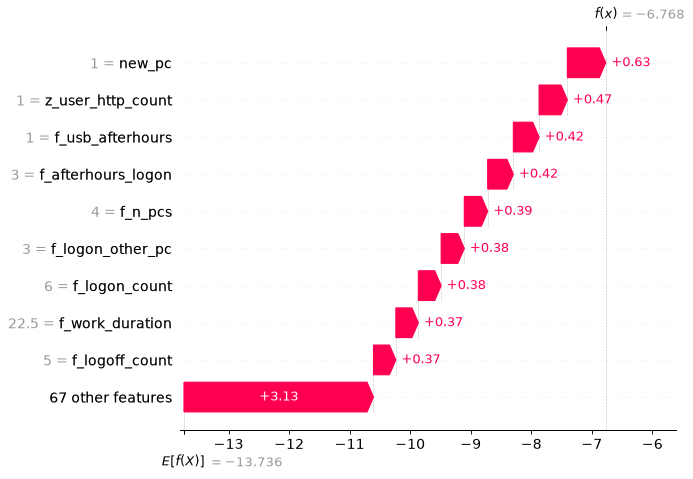

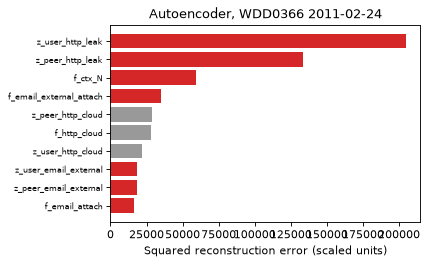

case 1 (scenario 1, true positive): WDD0366 on 2011-02-24
saved F7_case1_autoencoder_errors.pdf, F7_case1_autoencoder_errors.png, F7_case1_iforest_shap.pdf, F7_case1_iforest_shap.png


,feature,error,above_expected
0,z_user_http_leak,204591.593750,True
1,z_peer_http_leak,133708.375000,True
2,f_ctx_N,59596.218750,True
3,f_email_external_attach,35046.285156,True
4,z_peer_http_cloud,29042.398438,False
5,f_http_cloud,27887.359375,False
6,z_user_http_cloud,21614.644531,False
7,z_user_email_external,18497.228516,True
8,z_peer_email_external,18034.888672,True
9,f_email_attach,16113.822266,True


In [5]:
figures(1)

Step 5: the raw evidence for that user-day.

In [6]:
evidence(1)

case 1 (scenario 1, true positive): WDD0366 on 2011-02-24



logon: 11 rows


,date,user,pc,activity
0,2011-02-24 00:41:53,WDD0366,PC-8462,Logon
1,2011-02-24 01:01:44,WDD0366,PC-8462,Logoff
2,2011-02-24 07:39:23,WDD0366,PC-2125,Logon
3,2011-02-24 07:44:39,WDD0366,PC-2125,Logoff
4,2011-02-24 08:18:00,WDD0366,PC-0155,Logon
5,2011-02-24 12:28:46,WDD0366,PC-0155,Logon
6,2011-02-24 16:14:00,WDD0366,PC-0155,Logoff
7,2011-02-24 19:49:41,WDD0366,PC-0155,Logon
8,2011-02-24 22:05:27,WDD0366,PC-6009,Logon
9,2011-02-24 22:15:59,WDD0366,PC-6009,Logoff



device: 2 rows


,date,user,pc,activity
0,2011-02-24 22:07:28,WDD0366,PC-0155,Connect
1,2011-02-24 22:31:31,WDD0366,PC-0155,Disconnect



file: 0 rows

email: 11 rows


,date,user,pc,to,cc,bcc,from,size,attachments
0,2011-02-24 09:56:58,WDD0366,PC-0155,Kyla.Porter@bellsouth.net;TaShya_S_Mcgowan@verizon.net,WDD6532@optonline.net,NaN,WDD6532@optonline.net,31105,0
1,2011-02-24 10:13:29,WDD0366,PC-0155,Weiss-Blossom@juno.com,WDD6532@optonline.net,NaN,WDD6532@optonline.net,34914,0
2,2011-02-24 10:15:44,WDD0366,PC-0155,Joseph.Alan.Vaughan@dtaa.com;Jacqueline.Latifah.Miles@dtaa.com,TaShya.Savannah.Mcgowan@dtaa.com,Wesley.Dustin.Dickerson@dtaa.com,Wesley.Dustin.Dickerson@dtaa.com,28216,1
3,2011-02-24 10:21:21,WDD0366,PC-0155,Floyd-Arthur@gmail.com;Teagan_Townsend@comcast.net,Green-Maxwell@gmail.com;WDD6532@optonline.net,NaN,WDD6532@optonline.net,38952,2
4,2011-02-24 10:47:10,WDD0366,PC-0155,Jackson-Sutton@juno.com,WDD6532@optonline.net,NaN,WDD6532@optonline.net,24467,0
5,2011-02-24 12:36:50,WDD0366,PC-0155,Reyes-Matthew@boeing.com,Wesley.Dustin.Dickerson@dtaa.com,NaN,Wesley.Dustin.Dickerson@dtaa.com,14409,0
6,2011-02-24 12:38:51,WDD0366,PC-0155,Kenyon.Raja.Galloway@dtaa.com;Blossom.Keiko.Weiss@dtaa.com;Scarlet_Gutierrez@lockheedm...,Lenore.W.Morse@harris.com;Wesley.Dustin.Dickerson@dtaa.com,NaN,Wesley.Dustin.Dickerson@dtaa.com,18462,2
7,2011-02-24 12:42:14,WDD0366,PC-0155,Joseph.Alan.Vaughan@dtaa.com,NaN,Wesley.Dustin.Dickerson@dtaa.com,Wesley.Dustin.Dickerson@dtaa.com,23997,0
8,2011-02-24 12:42:23,WDD0366,PC-0155,Geoffrey.Jin.Tucker@dtaa.com,NaN,Wesley.Dustin.Dickerson@dtaa.com,Wesley.Dustin.Dickerson@dtaa.com,36466,0
9,2011-02-24 12:48:31,WDD0366,PC-0155,Kennedy.Robert.Vega@dtaa.com,NaN,Wesley.Dustin.Dickerson@dtaa.com,Wesley.Dustin.Dickerson@dtaa.com,12712,0



web: 46 rows; 115 visits, 49 after hours, 1 domains in a keyword category (first 25 shown)


,domain,category,visits,afterhours
0,wikileaks.org,leak,1,1
1,linkedin.com,other,13,7
2,eonline.com,other,9,2
3,live.com,other,7,3
4,ebay.com,other,6,5
5,imdb.com,other,6,2
6,pbskids.org,other,5,2
7,secureserver.net,other,5,1
8,netteller.com,other,4,1
9,conduit.com,other,3,0


**Case 1 narrative (Arva) [H]:** *4–6 sentences: what happened that day, and why the models did or did not flag it. Human-only.*

**Case 1 analyst verdict (Arva) [H]:** *escalate or not, and why. Human-only.*

## Case 2: scenario 2

Step 3: the day against the user's own previous 30 active days and against same-role peers that day.

In [7]:
baseline(2)

case 2 (scenario 2, true positive): CQW0652 on 2011-03-22


,feature,what,value,mean_previous_days,previous_days,z_user,z_peer
0,f_afterhours_events,after-hours events,17.0,9.40,30,2.19,3.05
1,f_file_copy,files copied,8.0,2.10,30,1.91,1.08
2,f_usb_connect,USB connects,5.0,1.97,30,1.49,1.92
3,f_http_count,web visits,29.0,33.00,30,-0.91,0.02
4,f_http_competitor,competitor-site visits,0.0,2.43,30,-0.82,-0.20


Step 4 (F7): what each model reacted to. Left to right in the SHAP waterfall, red pushes the Isolation Forest score towards "anomalous"; the values shown are the raw feature values. In the bar chart, red bars are values above what the autoencoder expected.

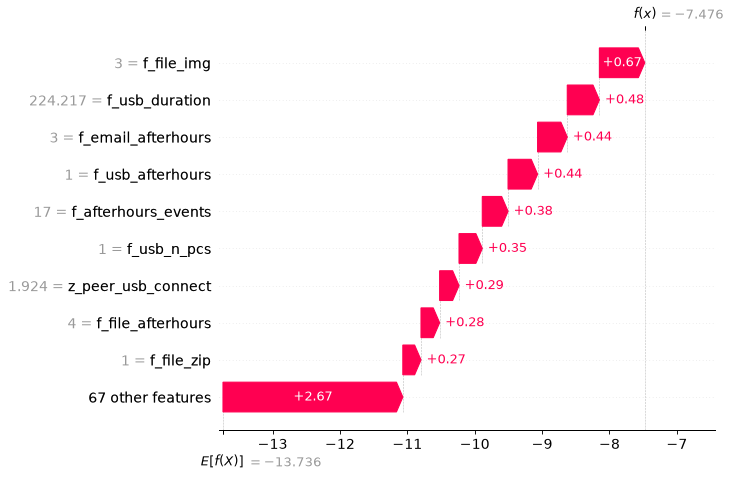

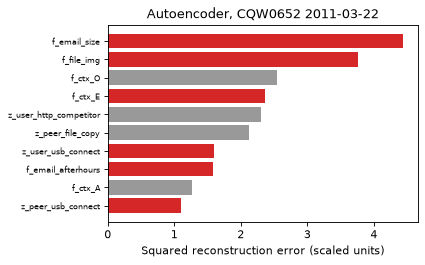

case 2 (scenario 2, true positive): CQW0652 on 2011-03-22
saved F7_case2_autoencoder_errors.pdf, F7_case2_autoencoder_errors.png, F7_case2_iforest_shap.pdf, F7_case2_iforest_shap.png


,feature,error,above_expected
0,f_email_size,4.438,True
1,f_file_img,3.759,True
2,f_ctx_O,2.538,False
3,f_ctx_E,2.362,True
4,z_user_http_competitor,2.301,False
5,z_peer_file_copy,2.115,False
6,z_user_usb_connect,1.594,True
7,f_email_afterhours,1.577,True
8,f_ctx_A,1.263,False
9,z_peer_usb_connect,1.096,True


In [8]:
figures(2)

Step 5: the raw evidence for that user-day.

In [9]:
evidence(2)

case 2 (scenario 2, true positive): CQW0652 on 2011-03-22



logon: 2 rows


,date,user,pc,activity
0,2011-03-22 09:10:00,CQW0652,PC-3449,Logon
1,2011-03-22 21:25:00,CQW0652,PC-3449,Logoff



device: 10 rows


,date,user,pc,activity
0,2011-03-22 10:57:19,CQW0652,PC-3449,Connect
1,2011-03-22 11:19:04,CQW0652,PC-3449,Disconnect
2,2011-03-22 12:02:43,CQW0652,PC-3449,Connect
3,2011-03-22 13:32:43,CQW0652,PC-3449,Disconnect
4,2011-03-22 15:28:06,CQW0652,PC-3449,Connect
5,2011-03-22 16:39:38,CQW0652,PC-3449,Disconnect
6,2011-03-22 18:20:11,CQW0652,PC-3449,Connect
7,2011-03-22 18:38:01,CQW0652,PC-3449,Disconnect
8,2011-03-22 20:06:03,CQW0652,PC-3449,Connect
9,2011-03-22 20:29:09,CQW0652,PC-3449,Disconnect



file: 8 rows


,date,user,pc,filename
0,2011-03-22 11:17:39,CQW0652,PC-3449,9JMGQPBH.jpg
1,2011-03-22 12:51:33,CQW0652,PC-3449,VDZEJ5UX.jpg
2,2011-03-22 16:29:24,CQW0652,PC-3449,0I8O7RFM.zip
3,2011-03-22 18:29:18,CQW0652,PC-3449,TBB5FQNM.jpg
4,2011-03-22 20:10:37,CQW0652,PC-3449,VZP9NNGM.doc
5,2011-03-22 20:11:08,CQW0652,PC-3449,G468POQN.doc
6,2011-03-22 20:13:25,CQW0652,PC-3449,BE1KZP6E.doc
7,2011-03-22 20:24:29,CQW0652,PC-3449,VBOUXHZ6.txt



email: 3 rows


,date,user,pc,to,cc,bcc,from,size,attachments
0,2011-03-22 19:59:09,CQW0652,PC-3449,Valentine.Lucian.Benjamin@dtaa.com,NaN,NaN,Chastity.Quyn.Wilkerson@dtaa.com,29955,0
1,2011-03-22 20:20:55,CQW0652,PC-3449,Heather.Cynthia.Leonard@dtaa.com,Astra-Brown@harris.com,NaN,Chastity.Quyn.Wilkerson@dtaa.com,23146,0
2,2011-03-22 21:10:26,CQW0652,PC-3449,Denise.Ifeoma.Doyle@dtaa.com,Regina_Thompson@lockheedmartin.com,NaN,Chastity.Quyn.Wilkerson@dtaa.com,66909,0



web: 20 rows; 29 visits, 7 after hours, 0 domains in a keyword category


,domain,category,visits,afterhours
0,wikipedia.org,other,3,0
1,compete.com,other,2,1
2,fiverr.com,other,2,1
3,linkedin.com,other,2,1
4,live.com,other,2,1
5,pcmag.com,other,2,0
6,yfrog.com,other,2,1
7,zendesk.com,other,2,0
8,abcnews.go.com,other,1,0
9,amazon.com,other,1,0


**Case 2 narrative (Arva) [H]:** *4–6 sentences: what happened that day, and why the models did or did not flag it. Human-only.*

**Case 2 analyst verdict (Arva) [H]:** *escalate or not, and why. Human-only.*

## Case 3: scenario 3

Step 3: the day against the user's own previous 30 active days and against same-role peers that day.

In [10]:
baseline(3)

case 3 (scenario 3, true positive): JLM0364 on 2011-04-28


,feature,what,value,mean_previous_days,previous_days,z_user,z_peer
0,f_afterhours_events,after-hours events,46.0,5.13,30,11.04,3.51
1,f_http_count,web visits,121.0,114.00,30,7.00,2.27
2,f_http_hack,keylogger/hacking-site visits,6.0,0.00,30,6.00,2.58
3,f_usb_connect,USB connects,2.0,0.00,30,2.00,0.11
4,f_email_recipients,email recipients,15.0,20.57,30,-1.03,-1.14


Step 4 (F7): what each model reacted to. Left to right in the SHAP waterfall, red pushes the Isolation Forest score towards "anomalous"; the values shown are the raw feature values. In the bar chart, red bars are values above what the autoencoder expected.

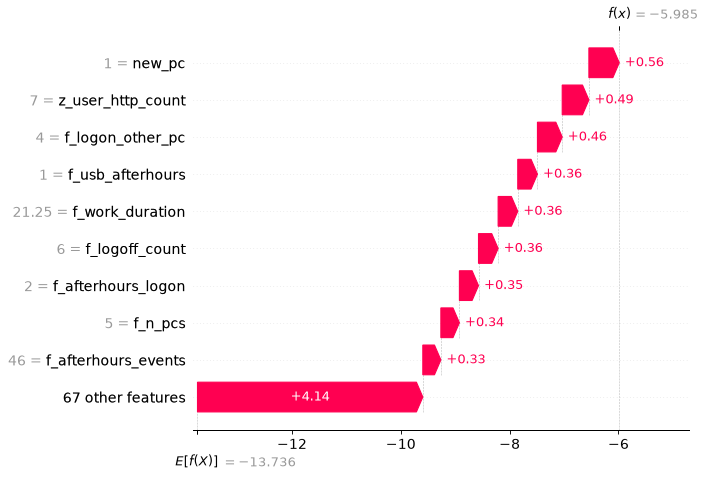

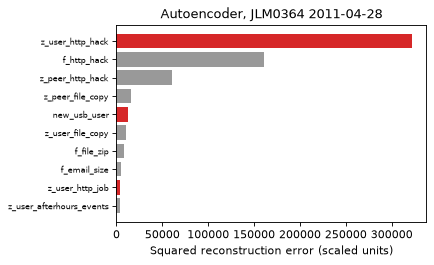

case 3 (scenario 3, true positive): JLM0364 on 2011-04-28
saved F7_case3_autoencoder_errors.pdf, F7_case3_autoencoder_errors.png, F7_case3_iforest_shap.pdf, F7_case3_iforest_shap.png


,feature,error,above_expected
0,z_user_http_hack,321777.406250,True
1,f_http_hack,160782.015625,False
2,z_peer_http_hack,60630.527344,False
3,z_peer_file_copy,16021.219727,False
4,new_usb_user,12702.599609,True
5,z_user_file_copy,10267.298828,False
6,f_file_zip,8072.021973,False
7,f_email_size,4501.733887,False
8,z_user_http_job,3886.085938,True
9,z_user_afterhours_events,3858.615967,False


In [11]:
figures(3)

Step 5: the raw evidence for that user-day.

In [12]:
evidence(3)

case 3 (scenario 3, true positive): JLM0364 on 2011-04-28



logon: 12 rows


,date,user,pc,activity
0,2011-04-28 01:57:04,JLM0364,PC-7931,Logon
1,2011-04-28 02:00:02,JLM0364,PC-7931,Logoff
2,2011-04-28 07:29:50,JLM0364,PC-0389,Logon
3,2011-04-28 07:35:46,JLM0364,PC-0389,Logoff
4,2011-04-28 08:19:00,JLM0364,PC-3791,Logon
5,2011-04-28 16:14:37,JLM0364,PC-6755,Logon
6,2011-04-28 16:26:00,JLM0364,PC-3791,Logoff
7,2011-04-28 16:33:08,JLM0364,PC-6755,Logoff
8,2011-04-28 17:52:43,JLM0364,PC-3791,Logon
9,2011-04-28 20:40:04,JLM0364,PC-8486,Logon



device: 4 rows


,date,user,pc,activity
0,2011-04-28 16:03:12,JLM0364,PC-3791,Connect
1,2011-04-28 16:14:28,JLM0364,PC-3791,Disconnect
2,2011-04-28 20:42:54,JLM0364,PC-8486,Connect
3,2011-04-28 20:46:52,JLM0364,PC-8486,Disconnect



file: 1 rows


,date,user,pc,filename
0,2011-04-28 16:06:52,JLM0364,PC-3791,7ESLQOMY.exe



email: 12 rows


,date,user,pc,to,cc,bcc,from,size,attachments
0,2011-04-28 09:50:07,JLM0364,PC-3791,Francis.Brian.Armstrong@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,21985,0
1,2011-04-28 11:18:20,JLM0364,PC-3791,Jackson.Rafael.Sutton@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,37470,3
2,2011-04-28 11:25:00,JLM0364,PC-3791,Dorothy.Marny.Goff@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,25690,0
3,2011-04-28 11:54:36,JLM0364,PC-3791,William.Price.Robles@dtaa.com;Joseph.Alan.Vaughan@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,36205,0
4,2011-04-28 12:03:04,JLM0364,PC-3791,Kennedy_Vega@hotmail.com,NaN,NaN,Jacqueline_L_Miles@sbcglobal.net,31368,0
5,2011-04-28 12:05:15,JLM0364,PC-3791,Robles-William@juno.com,NaN,NaN,Jacqueline_L_Miles@sbcglobal.net,35837,0
6,2011-04-28 12:57:33,JLM0364,PC-3791,Joseph.Alan.Vaughan@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,21899,0
7,2011-04-28 12:57:35,JLM0364,PC-3791,Francis.Brian.Armstrong@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,34839,0
8,2011-04-28 13:51:55,JLM0364,PC-3791,Jackson.Rafael.Sutton@dtaa.com,NaN,NaN,Jacqueline.Latifah.Miles@dtaa.com,22286,0
9,2011-04-28 13:55:58,JLM0364,PC-3791,TaShya.Savannah.Mcgowan@dtaa.com,Martina.Cassandra.Fields@dtaa.com,NaN,Jacqueline.Latifah.Miles@dtaa.com,34156,0



web: 47 rows; 121 visits, 39 after hours, 10 domains in a keyword category (first 25 shown)


,domain,category,visits,afterhours
0,northropgrumman.com,competitor,2,1
1,wellresearchedreviews.com,hack,2,0
2,actualkeylogger.com,hack,1,0
3,boeing.com,competitor,1,0
4,careerbuilder.com,job,1,0
5,indeed.com,job,1,0
6,raytheon.com,competitor,1,0
7,refog.com,hack,1,0
8,relytec.com,hack,1,0
9,webwatchernow.com,hack,1,0


**Case 3 narrative (Arva) [H]:** *4–6 sentences: what happened that day, and why the models did or did not flag it. Human-only.*

**Case 3 analyst verdict (Arva) [H]:** *escalate or not, and why. Human-only.*

## Case 4: the top normal day (false positive)

Step 3: the day against the user's own previous 30 active days and against same-role peers that day.

In [13]:
baseline(4)

case 4 (top normal day, false positive): AJF0370 on 2011-04-11


,feature,what,value,mean_previous_days,previous_days,z_user,z_peer
0,f_afterhours_events,after-hours events,34.00,16.20,30,1.81,2.49
1,f_email_recipients,email recipients,30.00,21.27,30,1.40,0.70
2,f_work_duration,hours between first logon and last logoff,21.58,17.37,30,1.02,1.00
3,f_usb_connect,USB connects,14.00,11.60,30,0.98,2.52
4,f_file_copy,files copied,37.00,29.43,30,0.86,3.55


Step 4 (F7): what each model reacted to. Left to right in the SHAP waterfall, red pushes the Isolation Forest score towards "anomalous"; the values shown are the raw feature values. In the bar chart, red bars are values above what the autoencoder expected.

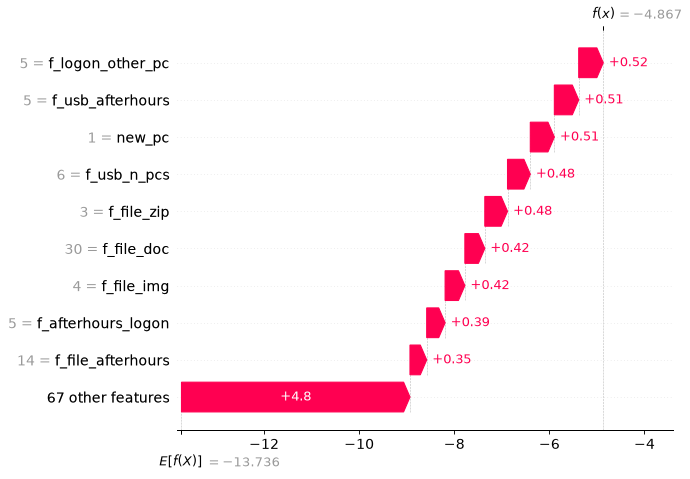

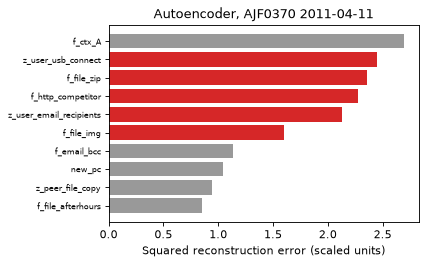

case 4 (top normal day, false positive): AJF0370 on 2011-04-11
saved F7_case4_autoencoder_errors.pdf, F7_case4_autoencoder_errors.png, F7_case4_iforest_shap.pdf, F7_case4_iforest_shap.png


,feature,error,above_expected
0,f_ctx_A,2.693,False
1,z_user_usb_connect,2.445,True
2,f_file_zip,2.360,True
3,f_http_competitor,2.274,True
4,z_user_email_recipients,2.129,True
5,f_file_img,1.597,True
6,f_email_bcc,1.137,False
7,new_pc,1.042,False
8,z_peer_file_copy,0.940,False
9,f_file_afterhours,0.850,False


In [14]:
figures(4)

Step 5: the raw evidence for that user-day.

In [15]:
evidence(4)

case 4 (top normal day, false positive): AJF0370 on 2011-04-11



logon: 13 rows


,date,user,pc,activity
0,2011-04-11 01:52:44,AJF0370,PC-1301,Logon
1,2011-04-11 02:04:15,AJF0370,PC-1301,Logoff
2,2011-04-11 02:38:48,AJF0370,PC-5061,Logon
3,2011-04-11 02:51:03,AJF0370,PC-5061,Logoff
4,2011-04-11 08:19:00,AJF0370,PC-8651,Logon
5,2011-04-11 13:17:11,AJF0370,PC-8651,Logon
6,2011-04-11 16:10:00,AJF0370,PC-8651,Logoff
7,2011-04-11 19:39:13,AJF0370,PC-6163,Logon
8,2011-04-11 19:45:35,AJF0370,PC-6163,Logoff
9,2011-04-11 23:00:18,AJF0370,PC-3723,Logon



device: 28 rows (first 25 shown)


,date,user,pc,activity
0,2011-04-11 01:58:43,AJF0370,PC-1301,Connect
1,2011-04-11 01:59:17,AJF0370,PC-1301,Disconnect
2,2011-04-11 02:45:58,AJF0370,PC-5061,Connect
3,2011-04-11 02:46:09,AJF0370,PC-5061,Disconnect
4,2011-04-11 08:24:08,AJF0370,PC-8651,Connect
5,2011-04-11 08:41:27,AJF0370,PC-8651,Disconnect
6,2011-04-11 08:50:31,AJF0370,PC-8651,Connect
7,2011-04-11 08:55:23,AJF0370,PC-8651,Disconnect
8,2011-04-11 09:31:57,AJF0370,PC-8651,Connect
9,2011-04-11 09:41:28,AJF0370,PC-8651,Disconnect



file: 37 rows (first 25 shown)


,date,user,pc,filename
0,2011-04-11 01:58:47,AJF0370,PC-1301,Z15GSWYQ.doc
1,2011-04-11 01:59:05,AJF0370,PC-1301,4KQKUI46.doc
2,2011-04-11 01:59:07,AJF0370,PC-1301,107TJUG7.doc
3,2011-04-11 02:45:59,AJF0370,PC-5061,68NYED65.doc
4,2011-04-11 02:46:02,AJF0370,PC-5061,2RHNS4VX.doc
5,2011-04-11 02:46:03,AJF0370,PC-5061,K0GXT3DO.pdf
6,2011-04-11 02:46:03,AJF0370,PC-5061,7XEO25RA.pdf
7,2011-04-11 02:46:04,AJF0370,PC-5061,BP9UVHUG.doc
8,2011-04-11 02:46:07,AJF0370,PC-5061,TDVSQN64.zip
9,2011-04-11 02:46:08,AJF0370,PC-5061,G7S8UXDT.pdf



email: 11 rows


,date,user,pc,to,cc,bcc,from,size,attachments
0,2011-04-11 08:44:39,AJF0370,PC-8651,Blossom.Keiko.Weiss@dtaa.com,NaN,NaN,Arthur.John.Floyd@dtaa.com,36374,0
1,2011-04-11 09:14:28,AJF0370,PC-8651,LBC5688@optonline.net;Jackson-Sutton@juno.com;TaShya_S_Mcgowan@verizon.net,Sydnee_L_Parsons@verizon.net,NaN,Floyd-Arthur@gmail.com,33001,0
2,2011-04-11 09:23:32,AJF0370,PC-8651,Jackson.Rafael.Sutton@dtaa.com;Eaton.Samuel.Jennings@dtaa.com,NaN,NaN,Arthur.John.Floyd@dtaa.com,34576,0
3,2011-04-11 13:39:40,AJF0370,PC-8651,Cody.Jonathan.Potter@dtaa.com;Francis.Brian.Armstrong@dtaa.com;Kyla.Jocelyn.Porter@dta...,Cain.Byron.Baldwin@dtaa.com,NaN,Arthur.John.Floyd@dtaa.com,27435,0
4,2011-04-11 13:43:17,AJF0370,PC-8651,Logan.Branden.Cherry@dtaa.com;Sonia.Anne.Kirkland@dtaa.com,TaShya.Savannah.Mcgowan@dtaa.com;Iola.H.Kemp@harris.com,NaN,Arthur.John.Floyd@dtaa.com,25806,0
5,2011-04-11 13:44:44,AJF0370,PC-8651,Noble.Merrill.Fuller@dtaa.com;Blossom.Keiko.Weiss@dtaa.com,Logan.Branden.Cherry@dtaa.com,NaN,Arthur.John.Floyd@dtaa.com,35586,0
6,2011-04-11 13:44:47,AJF0370,PC-8651,Hayes.Drake.Stephenson@dtaa.com;Jacqueline.Latifah.Miles@dtaa.com;Francis.Brian.Armstr...,TaShya.Savannah.Mcgowan@dtaa.com,NaN,Arthur.John.Floyd@dtaa.com,16180,1
7,2011-04-11 13:47:50,AJF0370,PC-8651,Francis.Brian.Armstrong@dtaa.com;Ariel.Ina.Barrett@dtaa.com;Hayes.Drake.Stephenson@dta...,Molly.Sacha.Zimmerman@dtaa.com,NaN,Arthur.John.Floyd@dtaa.com,32204,2
8,2011-04-11 13:48:07,AJF0370,PC-8651,Mannix.B.Ross@northropgrumman.com,NaN,NaN,Arthur.John.Floyd@dtaa.com,42562,0
9,2011-04-11 13:58:32,AJF0370,PC-8651,William.Price.Robles@dtaa.com,NaN,NaN,Arthur.John.Floyd@dtaa.com,38706,0



web: 57 rows; 114 visits, 0 after hours, 6 domains in a keyword category (first 25 shown)


,domain,category,visits,afterhours
0,careerbuilder.com,job,1,0
1,indeed.com,job,1,0
2,monster.com,job,1,0
3,northropgrumman.com,competitor,1,0
4,raytheon.com,competitor,1,0
5,simplyhired.com,job,1,0
6,basecamphq.com,other,4,0
7,citibank.com,other,4,0
8,ebay.com,other,4,0
9,huffingtonpost.com,other,4,0


**Case 4 narrative (Arva) [H]:** *4–6 sentences: what happened that day, and why the models did or did not flag it. Human-only.*

**Case 4 analyst verdict (Arva) [H]:** *escalate or not, and why. Human-only.*